# Capítulo 7 · Otros temas de RL

**Lectura:** pp. 173–198; §§7.1–7.8. [Capítulo original](https://arxiv.org/html/2412.05265v5#Ch7).

**Idea central:** el algoritmo depende también de cómo se obtiene información, de qué datos existen y de la escala temporal en la que se representa la tarea.

## Resumen por bloques

**§7.1 — Regret.** En lugar de mirar solo el rendimiento final, medimos lo perdido mientras aprendemos frente a un comparador. En un entorno estático puede ser la mejor política fija; en uno cambiante puede ser una secuencia de políticas óptimas. Las garantías de regret dinámico necesitan restricciones sobre el cambio del entorno. El criterio bayesiano promedia incertidumbre con un prior; el minimax protege frente a una clase de casos. No son objetivos intercambiables.

**§7.2 — Exploración.** Una formulación bayesiana aumenta el estado con creencias sobre el modelo; planificar en ese espacio incorpora el valor de aprender. Salvo casos especiales, es caro. Thompson sampling muestrea un modelo de su posterior y actúa como si fuera correcto; UCB usa una estimación optimista. PSRL extiende el muestreo posterior a MDP y mantiene una política coherente durante un episodio. Sus garantías dependen del modelo, del prior o de los intervalos utilizados.

**§7.3 — RL distribucional.** Aprender la distribución del retorno aporta más información que aprender solo su esperanza. Puede representarse mediante cuantiles o masas categóricas. No equivale a estimar incertidumbre epistémica sobre Q: una distribución amplia puede deberse al azar del entorno. Tampoco basta discretizar una media escalar para afirmar que se ha aprendido toda la distribución de retornos.

**§7.4 — Motivación intrínseca.** La curiosidad recompensa novedad o aprendizaje del mundo; otros métodos recompensan adquirir habilidades y alcanzar metas. Bonos de conteo, RND, ganancia de información, empowerment, currículos y Go-Explore atacan problemas distintos. El ejemplo de la “televisión ruidosa” muestra que error de predicción alto no siempre significa información útil: un agente puede quedarse mirando ruido irreducible.

**§7.5 — Jerarquía.** Una opción es una política temporalmente extendida, con conjunto de iniciación y regla de terminación. El nivel superior escoge habilidades; la ejecución puede durar varios pasos. Option-critic, MAXQ y otras variantes distribuyen decisiones y crédito. En jerarquías feudales, un gestor propone metas a un ejecutor. El descubrimiento de subtareas busca cuellos de botella o habilidades diversas. Una jerarquía impuesta puede acelerar aprendizaje y también restringir las soluciones posibles.

**§7.6 — Imitación.** Behavior cloning trata acciones expertas como etiquetas. Su problema secuencial es que pequeños errores pueden llevar a estados ausentes de las demostraciones. IRL busca una recompensa que explique al experto, pero generalmente no identifica una recompensa única. Los métodos de divergencia comparan distribuciones de ocupación estado-acción; GAIL y AIRL usan ideas adversarias.

**§7.7 — Offline RL.** Se aprende de un conjunto fijo sin poder probar nuevas acciones. La política puede elegir acciones sin soporte en los datos y explotar valores o modelos mal estimados. Restricciones de política, incertidumbre y penalizaciones conservadoras, como CQL, limitan este problema. Los modelos del mundo offline también requieren cautela ante predicciones fuera de distribución. Decision Transformer y modelos de trayectorias convierten partes del problema en modelado condicionado por retorno; pedir un retorno alto no garantiza que una acción lo cause en un mundo estocástico. Offline-to-online añade interacción posterior. DAgger corrige imitación pidiendo etiquetas expertas en estados visitados por el aprendiz: requiere interacción y acceso al experto.

**§7.8 — RL general.** AIXI combina una distribución sobre programas con planificación para definir un agente ideal. Es un referente teórico, no una receta ejecutable general: la mezcla universal no es computable en su forma ideal y la planificación es costosa. El cierre aborda agentes con capacidad y datos limitados.

## Ecuaciones esenciales

En nuestro bandit, con medias de recompensa $\mu_t(a)$,

$$
\mathcal{R}_T=\sum_{t=1}^T
\left[\max_a\mu_t(a)-\mu_t(a_t)\right].
$$

Es **pseudorregret**: usamos medias verdaderas para evaluar las acciones elegidas. El agente no conoce esas medias. En el escenario cambiante el comparador puede cambiar de brazo en cada instante.

Si una opción dura $\tau$ pasos, el objetivo temporal tiene la forma

$$
y=\sum_{k=0}^{\tau-1}\gamma^k r_{t+k}
+\gamma^\tau V(s_{t+\tau}).
$$

Usar solo $\gamma$ en el último término ignoraría su duración.

## Experimento 7 · Explorar y adaptarse

Comparamos $\epsilon$-greedy con media histórica, UCB1, Thompson Beta-Bernoulli y Thompson con olvido. Los cuatro brazos tienen probabilidades de éxito $(0.2,0.4,0.6,0.8)$. En el segundo escenario se invierte ese orden después de 2.000 de las 4.000 interacciones.

Cada método prueba los cuatro brazos al inicio. UCB1 usa $\hat\mu(a)+\sqrt{2\log(t)/N(a)}$. Thompson estándar empieza con Beta(1,1). En la variante con olvido, los pseudoconteos por encima del prior se multiplican por 0.98 antes de incorporar cada observación. Esta última es una heurística adaptativa, no el posterior exacto del modelo estacionario.

~~~bash
uv run python -m experimentos.ejecutar --capitulo 7
~~~

**Métrica:** pseudorregret acumulado, con 20 trayectorias independientes por método y escenario. El ruido de recompensas se comparte por réplica e instante entre métodos para facilitar la comparación; no se comparten las recompensas de acciones no elegidas.

**Resultado observado:** Thompson estándar funciona especialmente bien en el escenario fijo. Olvidar mejora su adaptación al cambio en este ejemplo, pero empeora mucho su rendimiento estacionario. UCB1 obtiene el menor regret cambiante entre las configuraciones probadas. El experimento no confirma un ganador universal ni que olvidar sea siempre mejor.

**Modificación:** cambia el instante de inversión, la separación entre brazos o el factor de olvido. Separa hiperparámetros de evaluación si quieres compararlos formalmente.

**Límite:** el laboratorio implementa §§7.1–7.2 y conecta con incertidumbre; los apartados de jerarquía, imitación y offline RL se resumen, pero no se reproducen aquí. Un bandit no prueba exploración profunda en MDP.



## Para el grupo

1. ¿Por qué una incertidumbre predictiva grande puede ser inútil para explorar?
2. ¿Qué no puedes aprender de un dataset que nunca probó cierta acción?
3. ¿Qué supuestos hacen útil una habilidad aprendida al cambiar de tarea?

**Conexión:** vuelve a la pregunta inicial: ¿qué sabe el agente y qué datos puede conseguir?


## Preparar la ejecución

Ejecuta todas las celdas en orden. El módulo contiene la implementación completa; la siguiente celda muestra su código. Cambia SEMILLA y REPLICAS para repetir. Los resultados del cuaderno se guardan en una carpeta separada.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import subprocess
import importlib
from IPython.display import display, Image, Code

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "experimentos" / "ejecutar.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CAPITULO = 7
SEMILLA = 2026
REPLICAS = 20
SALIDA = ROOT / "resultados" / "cuadernos"
modulo = importlib.import_module(f"experimentos.cap{CAPITULO:02d}")
display(Code(inspect.getsource(modulo), language="python"))

"""Cap. 7: exploración en bandits Bernoulli estacionarios y cambiantes."""
import numpy as np
import matplotlib.pyplot as plt
from .comun import guardar, curva, filas_finales, resumen_muestra

METODOS = ["ε-greedy", "UCB1", "Thompson", "Thompson con olvido"]

def simular(method, cambiante, seed, replicas, pasos=4000):
    rng = np.random.default_rng(seed)
    n = np.zeros((replicas, 4))
    sums = np.zeros_like(n)
    alpha, beta = np.ones_like(n), np.ones_like(n)
    regrets = np.zeros((replicas, pasos))
    idx = np.arange(replicas)
    # Ruido de recompensa separado del RNG de decisiones.
    reward_rng = np.random.default_rng(seed+1000000)
    for t in range(pasos):
        mu = np.array([.2, .4, .6, .8])
        if cambiante and t >= pasos//2:
            mu = mu[::-1]
        mean = np.divide(sums, n, out=np.zeros_like(sums), where=n > 0)
        if t < 4:
            a = np.full(replicas, t)
        elif method == "ε-greedy":
            a = (mean + rng.uniform(0, 1e-10, mean.shape)).argmax(axis=1)
            explore = rng.random(replicas) < .1
            a[explore] = rng.integers(0, 4, explore.sum())
        elif method == "UCB1":
            a = (mean + np.sqrt(2*np.log(t+1)/n)).argmax(axis=1)
        else:
            a = rng.beta(alpha, beta).argmax(axis=1)
        reward = (reward_rng.random(replicas) < mu[a]).astype(float)
        n[idx, a] += 1
        sums[idx, a] += reward
        if method == "Thompson con olvido":
            alpha = 1+.98*(alpha-1)
            beta = 1+.98*(beta-1)
        alpha[idx, a] += reward
        beta[idx, a] += 1-reward
        regrets[:, t] = mu.max()-mu[a]
    return regrets.cumsum(axis=1)

def ejecutar(out, seed=2026, replicas=20):
    arrays, rows, metrics = {}, [], {"pasos": 4000, "cambio_en": 2000,
                                   "epsilon": .1, "factor_olvido": .98}
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for col, cambiante in enumerate([False, True]):
        scenario = "Cambiante" if cambiante else "Estacionario"
        metrics[scenario] = {}
        for method in METODOS:
            regret = simular(method, cambiante, seed, replicas)
            name = scenario+" "+method
            arrays[name] = regret
            rows += filas_finales(name, regret[:, -1])
            curva(ax[col], np.arange(1, 4001), regret, method)
            metrics[scenario][method] = resumen_muestra(regret[:, -1])
        ax[col].set(xlabel="Interacción", ylabel="Pseudorregret acumulado", title=scenario)
        ax[col].legend()
        if cambiante:
            ax[col].axvline(2000, ls=":", color="black")
    return guardar(out, arrays, rows, metrics, fig)

## Ejecutar y registrar

El comando utiliza el mismo Python del kernel y conserva parámetros y hashes en su manifiesto. No necesita servicios externos.

In [2]:
command = [sys.executable, "-m", "experimentos.ejecutar",
           "--capitulo", str(CAPITULO), "--semilla", str(SEMILLA),
           "--replicas", str(REPLICAS), "--salida", str(SALIDA)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(completed.stdout)
carpeta = SALIDA / f"cap{CAPITULO:02d}"

Capítulo 7: completado en 0.84 s → /home/ialab/jairo_experiments/kevinMurphy/resultados/cuadernos/cap07



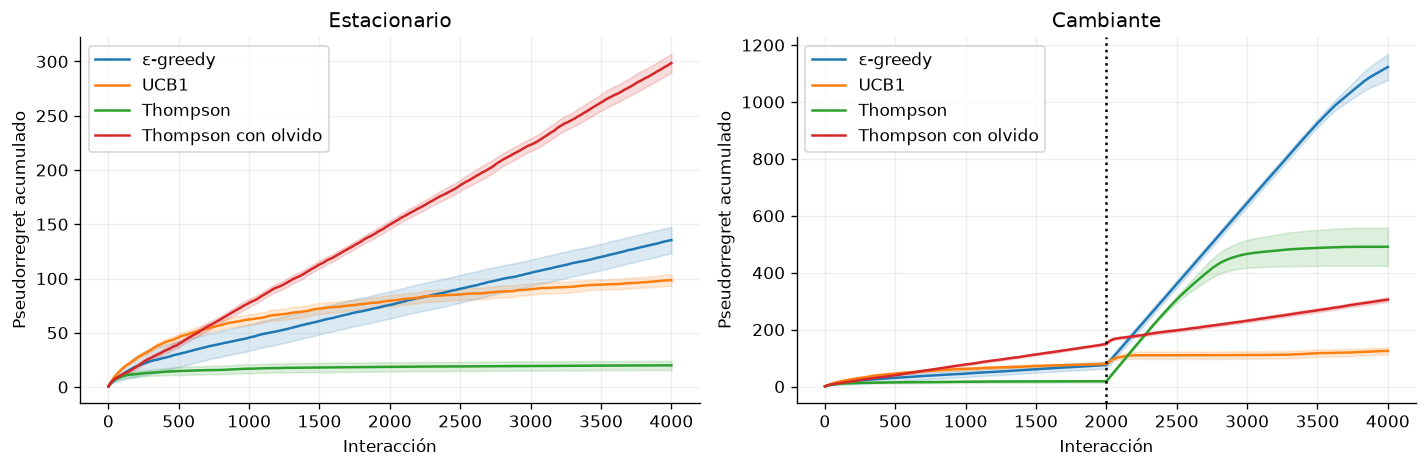

{
  "pasos": 4000,
  "cambio_en": 2000,
  "epsilon": 0.1,
  "factor_olvido": 0.98,
  "Estacionario": {
    "ε-greedy": {
      "media": 135.39000000000007,
      "ic95_aprox_semianchura": 12.112552118056264
    },
    "UCB1": {
      "media": 98.51000000000053,
      "ic95_aprox_semianchura": 5.450178356521503
    },
    "Thompson": {
      "media": 19.95999999999999,
      "ic95_aprox_semianchura": 4.241615803341687
    },
    "Thompson con olvido": {
      "media": 298.5499999999971,
      "ic95_aprox_semianchura": 8.511236825205367
    }
  },
  "Cambiante": {
    "ε-greedy": {
      "media": 1123.0300000000138,
      "ic95_aprox_semianchura": 46.10164620702194
    },
    "UCB1": {
      "media": 125.34,
      "ic95_aprox_semianchura": 11.81995726201186
    },
    "Thompson": {
      "media": 491.04000000000724,
      "ic95_aprox_semianchura": 66.81773825527081
    },
    "Thompson con olvido": {
      "media": 305.73999999999705,
      "ic95_aprox_semianchura": 7.833968100656395
   

In [3]:
display(Image(filename=str(carpeta / "figura.png")))
resumen = json.loads((carpeta / "resumen.json").read_text())
print(json.dumps(resumen, indent=2, ensure_ascii=False))

## Inspeccionar los datos

Las claves describen métricas; las dimensiones suelen ser réplica × instante, excepto los arrays auxiliares. Escribe una conclusión que apoyen los datos y una limitación. Prueba la modificación propuesta en el texto; antes de ejecutarla, predice su efecto.

In [4]:
import numpy as np
with np.load(carpeta / "datos.npz") as datos:
    for nombre in datos.files:
        print(nombre, datos[nombre].shape)

Estacionario ε-greedy (20, 4000)
Estacionario UCB1 (20, 4000)
Estacionario Thompson (20, 4000)
Estacionario Thompson con olvido (20, 4000)
Cambiante ε-greedy (20, 4000)
Cambiante UCB1 (20, 4000)
Cambiante Thompson (20, 4000)
Cambiante Thompson con olvido (20, 4000)


## Tu variante

Anota aquí: hipótesis, parámetro cambiado, métrica, resultado y limitación. Para modificar la dinámica o el algoritmo, edita el módulo mostrado o copia su función a una celda y experimenta con ella.

Fuente: [Kevin P. Murphy, Reinforcement Learning: An Overview, v5](https://arxiv.org/abs/2412.05265v5), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Resumen adaptado y experimento propio de esta guía.